<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HancockGPT2TabSHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Mounted at /content/drive
Rows with known target: 332
Class counts: {0: 191, 1: 141}
Train 215 {0: 123, 1: 92}
Validation 50 {0: 29, 1: 21}
Test 67 {0: 39, 1: 28}
Encoded input dimension: 19
Class weights: [0.87398374 1.16847826]


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 116354


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | train=0.5863 | val=0.6013 | ROC-AUC=0.7365 | PR-AUC=0.6538 | balanced accuracy=0.7151
Epoch 100/500 | train=0.4848 | val=0.5845 | ROC-AUC=0.7496 | PR-AUC=0.7465 | balanced accuracy=0.7471
Epoch 150/500 | train=0.4495 | val=0.5636 | ROC-AUC=0.7709 | PR-AUC=0.7528 | balanced accuracy=0.7389
Epoch 200/500 | train=0.4240 | val=0.6416 | ROC-AUC=0.7611 | PR-AUC=0.7347 | balanced accuracy=0.7430
Epoch 250/500 | train=0.3491 | val=0.9603 | ROC-AUC=0.6954 | PR-AUC=0.6668 | balanced accuracy=0.6823
Epoch 300/500 | train=0.3286 | val=1.1056 | ROC-AUC=0.6708 | PR-AUC=0.6589 | balanced accuracy=0.6691
Epoch 350/500 | train=0.2710 | val=1.3958 | ROC-AUC=0.6773 | PR-AUC=0.6505 | balanced accuracy=0.6782
Epoch 400/500 | train=0.2525 | val=1.6540 | ROC-AUC=0.6379 | PR-AUC=0.5966 | balanced accuracy=0.6281
Epoch 450/500 | train=0.2430 | val=1.8618 | ROC-AUC=0.6149 | PR-AUC=0.5878 | balanced accuracy=0.6412
Epoch 500/500 | train=0.1826 | val=2.2067 | ROC-AUC=0.6232 | PR-AUC=0.5697 | balanc

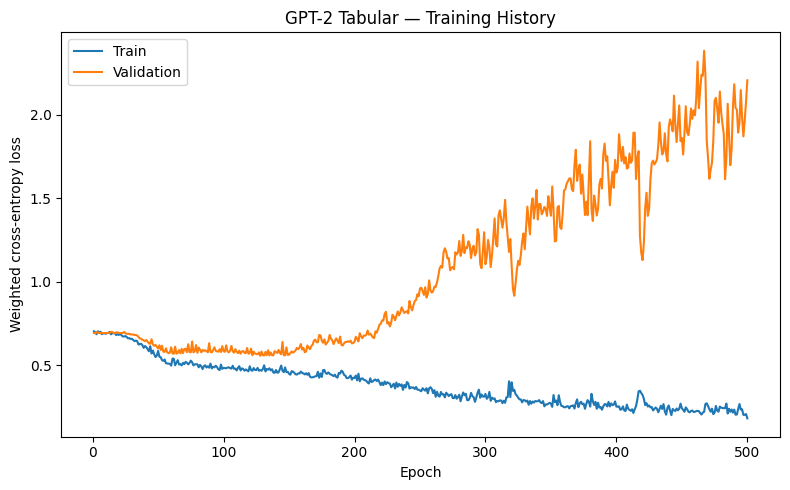


CHECKPOINT: best_val_loss | Epoch: 128
Checkpoint                      best_val_loss
Epoch                                     128
Threshold                            0.345092
Validation_Loss                      0.557112
Validation_ROC_AUC                   0.779146
Validation_PR_AUC                    0.754429
Validation_Balanced_Accuracy         0.773399
Balanced_Accuracy                    0.731227
F1                                   0.707692
ROC_AUC                              0.807692
PR_AUC                               0.782279
Confusion matrix:
 [[25 14]
 [ 5 23]]
              precision    recall  f1-score   support

HPV Negative     0.8333    0.6410    0.7246        39
HPV Positive     0.6216    0.8214    0.7077        28

    accuracy                         0.7164        67
   macro avg     0.7275    0.7312    0.7162        67
weighted avg     0.7449    0.7164    0.7176        67


CHECKPOINT: best_val_roc_auc | Epoch: 148
Checkpoint                      best_val_roc_a

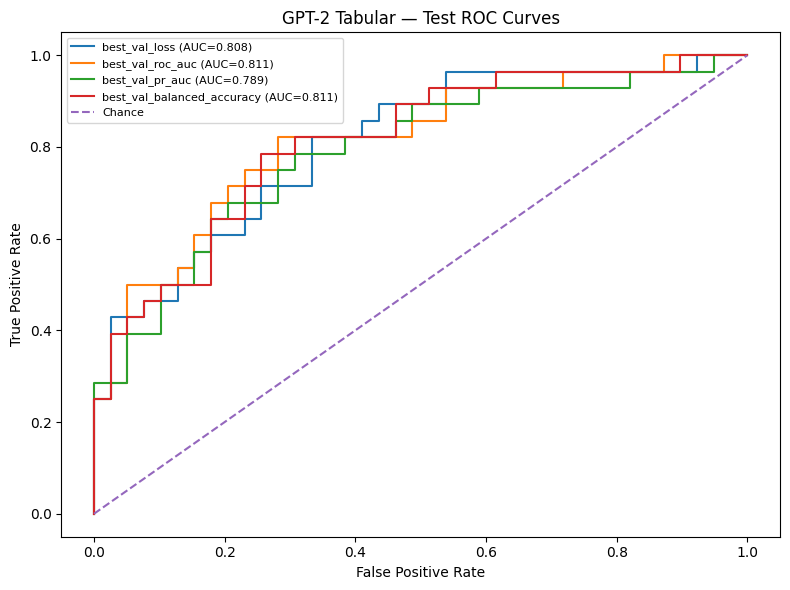

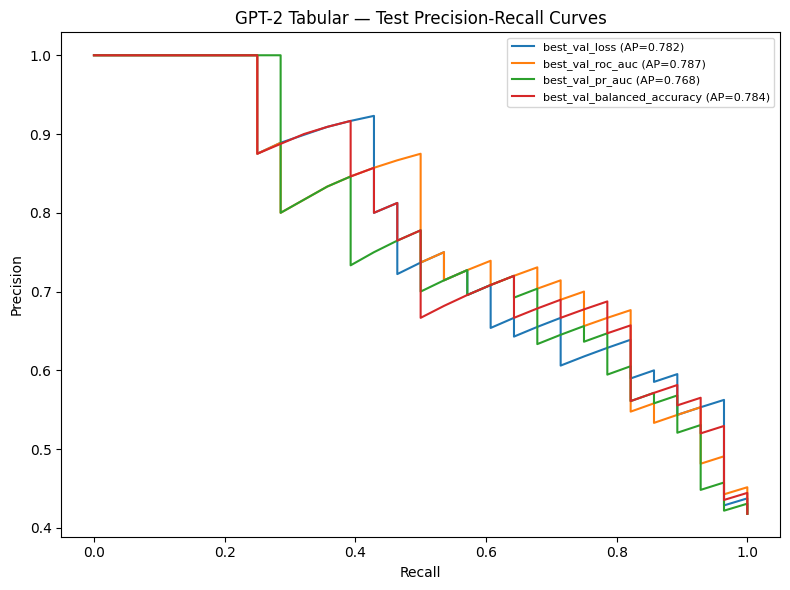

All results saved to: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results
Files: ['HANCOCK_GPT2_Tabular_Frozen_confidence_intervals.csv', 'HANCOCK_GPT2_Tabular_ROC_AUC_Summary.csv', 'HANCOCK_GPT2_Tabular_ROC_CI.csv', 'HANCOCK_GPT2_Tabular_ROC_Curve_CI.png', 'HANCOCK_GPT2_Tabular_Test_PR_Curve.png', 'HANCOCK_GPT2_Tabular_Test_ROC_Curve.png', 'HANCOCK_LIME_Feature_Importance.csv', 'HANCOCK_LIME_Feature_Importance.png', 'HANCOCK_LIME_Patient_Results.csv', 'HANCOCK_SHAP_Beeswarm.png', 'HANCOCK_SHAP_Feature_Importance.csv', 'checkpoints', 'metrics_all_checkpoints.csv', 'run_summary.json', 'tabular_preprocessor.joblib', 'test_pr_curves.png', 'test_predictions_all_checkpoints.csv', 'test_roc_curves.png', 'training_history.csv', 'training_history.png']


In [2]:

# HANCOCK HPV — GPT-2 TABULAR CLASSIFIER
# Matched protocol: clinical narrative reference
# 65/15/20 stratified split | Seed 42 | Batch 64 | 500 epochs
# No SMOTE | Four validation-selected checkpoints

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive
from transformers import GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
MODEL_NAME = "openai-community/gpt2"


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "GPT2_Tabular_Hancock_Frozen_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD AND PREPARE DATA
# ============================================================

def load_json_table(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if isinstance(obj.get(key), list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table: {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)
pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

target_col = next(
    (
        c for c in [
            "hpv_association_p16",
            "hpv_association_p16_path"
        ]
        if c in df.columns
    ),
    None
)

if target_col is None:
    raise KeyError("Could not find hpv_association_p16 target.")

feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature, candidates in feature_candidates.items():
    found = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if found is None:
        raise KeyError(
            f"Missing predictor {feature}; checked {candidates}"
        )

    if found != feature:
        rename_map[found] = feature

df = df.rename(columns=rename_map)
features = list(feature_candidates)


def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()

print("Rows with known target:", len(df))
print(
    "Class counts:",
    df["HPV_Label"].value_counts().sort_index().to_dict()
)


# ============================================================
# 3. STRATIFIED 65/15/20 TRAIN/VALIDATION/TEST SPLIT
# ============================================================

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train, val, test = [
    part.reset_index(drop=True)
    for part in (train, val, test)
]

for name, part in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        name,
        len(part),
        part["HPV_Label"].value_counts().sort_index().to_dict()
    )

X_train_df, X_val_df, X_test_df = [
    part[features].copy()
    for part in (train, val, test)
]

y_train, y_val, y_test = [
    part["HPV_Label"].to_numpy(dtype=np.int64)
    for part in (train, val, test)
]


# ============================================================
# 4. IMPUTATION AND ONE-HOT ENCODING
# ============================================================

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [
    c for c in features if c not in numeric_features
]

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df[
    "age_at_initial_diagnosis"
].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

for col in categorical_features:
    modes = X_train_df[col].dropna().astype(str).mode()
    fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    for frame in (X_train_df, X_val_df, X_test_df):
        frame[col] = frame[col].fillna(fill_value)
        frame[col] = frame[col].astype(str).replace({
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        })

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", encoder, categorical_features)
])

X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

print("Encoded input dimension:", X_train.shape[1])


# ============================================================
# 5. CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in training data."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Class weights:", weights)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val, dtype=torch.float32, device=device
)
y_val_t = torch.tensor(
    y_val, dtype=torch.long, device=device
)
X_test_t = torch.tensor(
    X_test, dtype=torch.float32, device=device
)


# ============================================================
# 6. TABULAR GPT-2 ARCHITECTURE — PRESERVED
# ============================================================

class GPT2TabularClassifier(nn.Module):
    def __init__(self, n_features, dropout=0.1):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze all GPT-2 backbone parameters
        for param in self.gpt2.parameters():
            param.requires_grad = False

        hidden = self.gpt2.config.hidden_size
        self.feature_projection = nn.Linear(1, hidden)

        self.feature_embedding = nn.Parameter(
            torch.zeros(1, n_features, hidden)
        )
        nn.init.normal_(
            self.feature_embedding,
            mean=0.0,
            std=0.02
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Dropout(dropout),
            nn.Linear(hidden, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        tokens = self.feature_projection(x.unsqueeze(-1))
        tokens = tokens + self.feature_embedding

        hidden = self.gpt2(
            inputs_embeds=tokens
        ).last_hidden_state

        return self.classifier(hidden.mean(dim=1))


model = GPT2TabularClassifier(
    X_train.shape[1],
    DROPOUT
).to(device)
# VERIFY GPT-2 BACKBONE IS FROZEN
gpt2_trainable = sum(
    p.numel() for p in model.gpt2.parameters()
    if p.requires_grad
)

other_trainable = sum(
    p.numel() for name, p in model.named_parameters()
    if not name.startswith("gpt2.") and p.requires_grad
)

print("GPT-2 trainable parameters:", gpt2_trainable)
print("Other trainable parameters:", other_trainable)

assert gpt2_trainable == 0, "GPT-2 is NOT frozen!"
assert other_trainable > 0, "Tabular/classifier layers are NOT trainable!"



# Match clinical narrative weighted-loss calculation
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )
    return (losses * class_weights[labels]).mean()


def evaluate_loss():
    model.eval()

    with torch.no_grad():
        return weighted_classification_loss(
            model(X_val_t),
            y_val_t
        ).item()


optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


def predict_probabilities(X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


# ============================================================
# 7. VALIDATION THRESHOLD AND METRICS
# ============================================================

def select_threshold(y_true, probabilities):
    thresholds = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                y_true,
                (probabilities >= t).astype(int)
            )
        )
        for t in thresholds
    ]

    # Maximise balanced accuracy; ties closest to 0.5
    return max(
        results,
        key=lambda x: (x[1], -abs(x[0] - 0.5))
    )


def validation_metrics():
    p = predict_probabilities(X_val_t)
    threshold, bal_acc = select_threshold(y_val, p)

    roc_auc = (
        roc_auc_score(y_val, p)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "balanced_accuracy": float(bal_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(average_precision_score(y_val, p))
    }


checkpoint_specs = {
    "best_val_loss": (
        "gpt2_best_val_loss.pt", "min"
    ),
    "best_val_roc_auc": (
        "gpt2_best_val_roc_auc.pt", "max"
    ),
    "best_val_pr_auc": (
        "gpt2_best_val_pr_auc.pt", "max"
    ),
    "best_val_balanced_accuracy": (
        "gpt2_best_val_balanced_accuracy.pt", "max"
    )
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


# ============================================================
# 8. TRAIN — 500 EPOCHS
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum = 0.0
    n_seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        loss = weighted_classification_loss(
            model(xb), yb
        )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(yb)
        n_seen += len(yb)

    train_loss = loss_sum / max(n_seen, 1)
    val_loss = evaluate_loss()
    vm = validation_metrics()

    history.append({
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": float(vm["roc_auc"]),
        "val_pr_auc": float(vm["pr_auc"]),
        "val_balanced_accuracy": float(vm["balanced_accuracy"]),
        "val_threshold": float(vm["threshold"])
    })

    scores = {
        "best_val_loss": val_loss,
        "best_val_roc_auc": vm["roc_auc"],
        "best_val_pr_auc": vm["pr_auc"],
        "best_val_balanced_accuracy": vm["balanced_accuracy"]
    }

    for key, score in scores.items():
        direction = checkpoint_specs[key][1]

        improved = (
            score < best_values[key]
            if direction == "min"
            else score > best_values[key]
        )

        if not np.isfinite(score) or not improved:
            continue

        best_values[key] = float(score)
        best_epochs[key] = int(epoch)

        # Store only standard Python scalar metadata.
        checkpoint_data = {
            "epoch": int(epoch),
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "validation_loss": float(val_loss),
            "validation_roc_auc": float(vm["roc_auc"]),
            "validation_pr_auc": float(vm["pr_auc"]),
            "validation_balanced_accuracy": float(
                vm["balanced_accuracy"]
            ),
            "validation_threshold": float(vm["threshold"])
        }

        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs[key][0]
            )
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{MAX_EPOCHS} | "
            f"train={train_loss:.4f} | "
            f"val={val_loss:.4f} | "
            f"ROC-AUC={vm['roc_auc']:.4f} | "
            f"PR-AUC={vm['pr_auc']:.4f} | "
            f"balanced accuracy={vm['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs; ran {len(history)}."
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

print("Best checkpoint epochs:", best_epochs)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("GPT-2 Tabular — Training History")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)
plt.show()


# ============================================================
# 9. TEST EACH SELECTED CHECKPOINT
# ============================================================

all_metrics = []
all_predictions = []
test_probabilities = {}

for name, (filename, _) in checkpoint_specs.items():
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, filename
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}. "
            "Run the training section first, or check Drive."
        )

    # FIX FOR PYTORCH 2.6+:
    # Use weights_only=False only for trusted checkpoints
    # generated by this notebook.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    val_prob = predict_probabilities(X_val_t)
    test_prob = predict_probabilities(X_test_t)
    test_probabilities[name] = test_prob

    # Select threshold from validation data only.
    threshold, val_bal_acc = select_threshold(
        y_val, val_prob
    )

    test_pred = (test_prob >= threshold).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test, test_prob
    )

    metrics = {
        "Checkpoint": name,
        "Epoch": int(checkpoint["epoch"]),
        "Threshold": float(threshold),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y_test, test_pred)
        ),
        "F1": float(
            f1_score(y_test, test_pred, zero_division=0)
        ),
        "ROC_AUC": float(test_roc_auc),
        "PR_AUC": float(test_pr_auc)
    }

    all_metrics.append(metrics)

    all_predictions.append(pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": name,
        "epoch": int(checkpoint["epoch"]),
        "threshold": float(threshold)
    }))

    print("\n", "=" * 55)
    print("CHECKPOINT:", name, "| Epoch:", checkpoint["epoch"])
    print(pd.Series(metrics).to_string())

    print(
        "Confusion matrix:\n",
        confusion_matrix(y_test, test_pred, labels=[0, 1])
    )

    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

pd.DataFrame(all_metrics).to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "test_predictions_all_checkpoints.csv"
    ),
    index=False
)


# ============================================================
# 10. TEST ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    if len(np.unique(y_test)) < 2:
        continue

    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GPT-2 Tabular — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_roc_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 11. TEST PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)

    plt.plot(
        recall, precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GPT-2 Tabular — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_pr_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 12. SAVE PREPROCESSOR AND RUN SUMMARY
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "tabular_preprocessor.joblib")
)

summary = {
    "seed": SEED,
    "model_name": MODEL_NAME,
    "epochs": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "original_predictors": features,
    "encoded_feature_count": int(X_train.shape[1]),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "smote": False,
    "gradient_clipping": False,
    "gpt2_fine_tuned": True,
    "class_weights": [
        float(w) for w in class_weights.detach().cpu().tolist()
    ],
    "checkpoint_selection": (
        "Best validation loss, ROC-AUC, PR-AUC "
        "and balanced accuracy"
    ),
    "threshold_selection": (
        "Maximise validation balanced accuracy over unique "
        "scores plus 0 and 1; ties closest to 0.5"
    ),
    "loss": (
        "Mean per-example cross-entropy multiplied "
        "by target-class weight"
    ),
    "best_epochs": {
        k: int(v) for k, v in best_epochs.items()
    }
}

with open(
    os.path.join(OUT_DIR, "run_summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("All results saved to:", OUT_DIR)
print("Files:", sorted(os.listdir(OUT_DIR)))


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Loading checkpoint: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/checkpoints/gpt2_best_val_roc_auc.pt
Checkpoint epoch: 148
Model loaded successfully.
Encoded feature count: 19

Encoded columns grouped into original predictors:
Age at initial diagnosis: 1 encoded column(s)
Sex: 2 encoded column(s)
Smoking status: 3 encoded column(s)
Primary tumour site: 2 encoded column(s)
Primarily metastasis: 2 encoded column(s)
pN stage: 9 encoded column(s)

TEST SET PERFORMANCE — EPOCH 148
ROC-AUC: 0.811355
Average Precision (PR-AUC): 0.786516
Number of test patients: 67

ROC CURVE POINTS
     FPR      TPR  Threshold
0.000000 0.000000        inf
0.000000 0.035714   0.998837
0.000000 0.250000   0.730596
0.025641 0.250000   0.702241
0.025641 0.285714   0.658916
0.051282 0.285714   0.640643
0.051282 0.357143   0.638783
0.051282 0.500000   0.568713
0.12820

  0%|          | 0/67 [00:00<?, ?it/s]

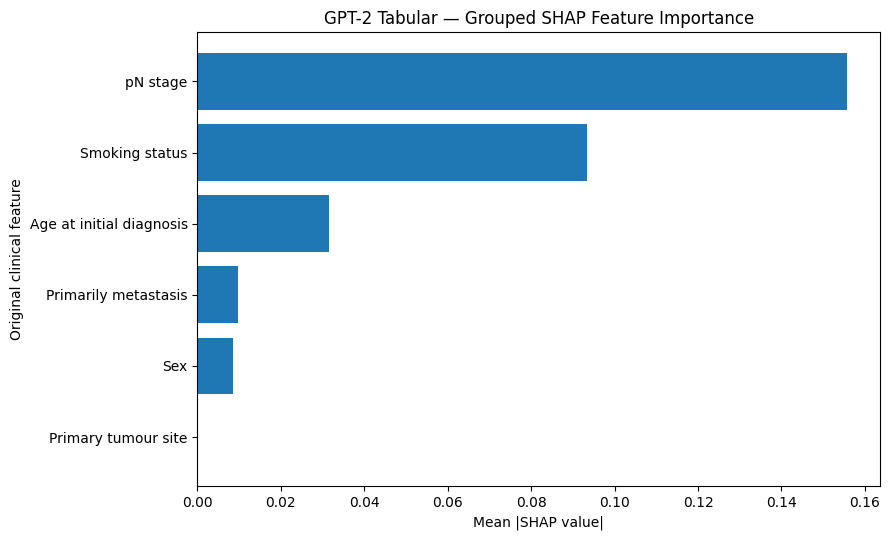


Calculating grouped LIME explanation...


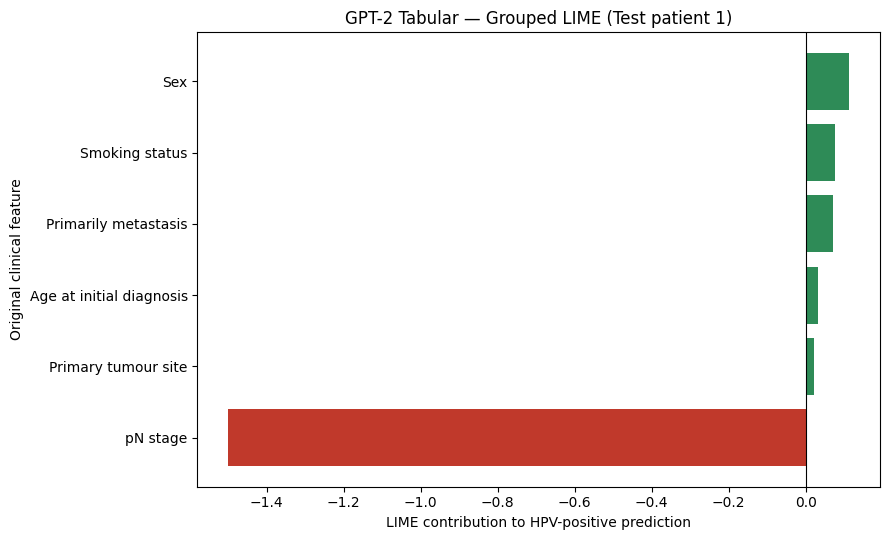


FILES CREATED
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Grouped_SHAP.png
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Grouped_LIME.png
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_ROC_Points.csv
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_PR_Points.csv
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Test_Predictions.csv
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Grouped_SHAP_Values.csv
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Grouped_SHAP_Importance.csv
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Grouped_LIME_Importance.csv

ZIP file: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ============================================================
# GPT-2 TABULAR (FROZEN) — EPOCH 148
# GROUPED SHAP + GROUPED LIME (6 ORIGINAL FEATURES)
# ROC / PR CURVE COORDINATES + PATIENT PREDICTIONS
#
# Outputs:
#   1. One grouped SHAP PNG
#   2. One grouped LIME PNG
#   3. ROC curve points CSV
#   4. PR curve points CSV
#   5. Test predictions CSV
#   6. ZIP containing the above files
# ============================================================

!pip -q install shap lime

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)
from google.colab import files

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

SEED = 42
EXPECTED_EPOCH = 148
LIME_TEST_ROW = 0

np.random.seed(SEED)

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD THE BEST ROC-AUC CHECKPOINT
# ------------------------------------------------------------

checkpoint_dir = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results/checkpoints"
)

# Find the ROC-AUC checkpoint without assuming its exact filename.
possible_checkpoints = (
    glob.glob(os.path.join(checkpoint_dir, "*roc_auc*.pt")) +
    glob.glob(os.path.join(checkpoint_dir, "*ROC_AUC*.pt"))
)

if not possible_checkpoints:
    raise FileNotFoundError(
        "Could not find the ROC-AUC checkpoint in: " + checkpoint_dir
    )

checkpoint_path = possible_checkpoints[0]
print("Loading checkpoint:", checkpoint_path)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Support common checkpoint dictionary formats.
if isinstance(checkpoint, dict):
    state_dict = None

    for key in [
        "model_state_dict",
        "state_dict",
        "model"
    ]:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            state_dict = checkpoint[key]
            break

    if state_dict is not None:
        model.load_state_dict(state_dict)

    saved_epoch = checkpoint.get(
        "epoch",
        checkpoint.get("best_epoch", None)
    )

    if saved_epoch is not None:
        saved_epoch = int(saved_epoch)
        print("Checkpoint epoch:", saved_epoch)

        if saved_epoch != EXPECTED_EPOCH:
            raise ValueError(
                f"Expected epoch {EXPECTED_EPOCH}, "
                f"but checkpoint reports epoch {saved_epoch}."
            )

model = model.to(device)
model.eval()

print("Model loaded successfully.")

# ------------------------------------------------------------
# 3. PREPARE DATA AND LABELS
# ------------------------------------------------------------

X_train_np = np.asarray(X_train, dtype=np.float32)
X_test_np = np.asarray(X_test, dtype=np.float32)

y_array = np.asarray(y_test)

# Support either integer labels or one-hot labels.
if y_array.ndim == 2:
    y_true = np.argmax(y_array, axis=1).astype(int)
else:
    y_true = y_array.reshape(-1).astype(int)

if len(X_test_np) != len(y_true):
    raise ValueError("X_test and y_test have different lengths.")

if LIME_TEST_ROW >= len(X_test_np):
    raise ValueError("LIME_TEST_ROW is outside the test set.")

# ------------------------------------------------------------
# 4. GET THE 19 ENCODED FEATURE NAMES
# ------------------------------------------------------------

feature_names = list(preprocessor.get_feature_names_out())

if len(feature_names) != X_train_np.shape[1]:
    raise ValueError(
        "The number of feature names does not match "
        "the encoded input dimension."
    )

print("Encoded feature count:", len(feature_names))

# ------------------------------------------------------------
# 5. GROUP ENCODED FEATURES INTO SIX ORIGINAL FEATURES
# ------------------------------------------------------------

original_features = [
    "Age at initial diagnosis",
    "Sex",
    "Smoking status",
    "Primary tumour site",
    "Primarily metastasis",
    "pN stage"
]

def normalise_name(name):
    return (
        str(name)
        .lower()
        .replace(" ", "")
        .replace("_", "")
        .replace("-", "")
        .replace("/", "")
        .replace(".", "")
    )

feature_patterns = {
    "Age at initial diagnosis": "ageatinitialdiagnosis",
    "Sex": "sex",
    "Smoking status": "smokingstatus",
    "Primary tumour site": "primarytumorsite",
    "Primarily metastasis": "primarily metastasis".replace(" ", ""),
    "pN stage": "pnstage"
}

# Map each encoded column to one of the six original predictors.
group_indices = {name: [] for name in original_features}
unmatched_features = []

for index, encoded_name in enumerate(feature_names):
    normalised = normalise_name(encoded_name)

    matched = False

    for original_name, pattern in feature_patterns.items():
        if pattern in normalised:
            group_indices[original_name].append(index)
            matched = True
            break

    if not matched:
        unmatched_features.append(encoded_name)

if unmatched_features:
    raise ValueError(
        "Some encoded columns could not be assigned to an original "
        "feature. Check these names:\n" + str(unmatched_features)
    )

for name in original_features:
    if len(group_indices[name]) == 0:
        raise ValueError(
            f"No encoded columns were found for: {name}"
        )

print("\nEncoded columns grouped into original predictors:")
for name in original_features:
    print(f"{name}: {len(group_indices[name])} encoded column(s)")

# ------------------------------------------------------------
# 6. PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_positive_probability(data):
    data = np.asarray(data, dtype=np.float32)

    tensor = torch.as_tensor(
        data,
        dtype=torch.float32,
        device=device
    )

    model.eval()

    with torch.no_grad():
        output = model(tensor)

        # Support models that return a tuple/list.
        if isinstance(output, (tuple, list)):
            output = output[0]

        # Convert two-class logits to probabilities.
        if output.ndim == 1:
            probabilities = torch.sigmoid(output)
        elif output.shape[1] == 1:
            probabilities = torch.sigmoid(output[:, 0])
        else:
            probabilities = torch.softmax(output, dim=1)[:, 1]

    return probabilities.detach().cpu().numpy().reshape(-1)


def predict_proba_for_lime(data):
    positive = predict_positive_probability(data)
    negative = 1.0 - positive
    return np.column_stack([negative, positive])


# ------------------------------------------------------------
# 7. TEST PREDICTIONS + ROC AND PR POINTS
# ------------------------------------------------------------

y_score = predict_positive_probability(X_test_np)

if len(y_score) != len(y_true):
    raise ValueError("Predictions and test labels have different lengths.")

roc_auc = roc_auc_score(y_true, y_score)
average_precision = average_precision_score(y_true, y_score)

# ROC coordinates
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)

roc_points = pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
})

roc_csv = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_ROC_Points.csv"
)
roc_points.to_csv(roc_csv, index=False)

# Precision-recall coordinates
precision, recall, pr_thresholds = precision_recall_curve(
    y_true,
    y_score
)

# sklearn returns one more precision/recall point than thresholds.
pr_thresholds_aligned = np.append(pr_thresholds, np.nan)

pr_points = pd.DataFrame({
    "Recall": recall,
    "Precision": precision,
    "Threshold": pr_thresholds_aligned
})

pr_csv = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_PR_Points.csv"
)
pr_points.to_csv(pr_csv, index=False)

# Save individual test predictions.
patient_ids = (
    test["patient_id"].to_numpy()
    if "patient_id" in test.columns
    else np.arange(len(y_true))
)

predictions_df = pd.DataFrame({
    "patient_id": patient_ids,
    "y_true": y_true,
    "predicted_probability_HPV_positive": y_score,
    "model": "GPT-2 Tabular Frozen",
    "checkpoint": "best_val_roc_auc",
    "epoch": EXPECTED_EPOCH
})

predictions_csv = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_Test_Predictions.csv"
)
predictions_df.to_csv(predictions_csv, index=False)

print("\n========================================")
print("TEST SET PERFORMANCE — EPOCH 148")
print("========================================")
print(f"ROC-AUC: {roc_auc:.6f}")
print(f"Average Precision (PR-AUC): {average_precision:.6f}")
print(f"Number of test patients: {len(y_true)}")

print("\n========================================")
print("ROC CURVE POINTS")
print("========================================")
print(roc_points.to_string(index=False))

print("\n========================================")
print("PRECISION-RECALL CURVE POINTS")
print("========================================")
print(pr_points.to_string(index=False))

print("\n========================================")
print("TEST PREDICTIONS")
print("========================================")
print(predictions_df.to_string(index=False))

# ------------------------------------------------------------
# 8. SHAP — GROUPED INTO SIX ORIGINAL FEATURES
# ------------------------------------------------------------

print("\nCalculating grouped SHAP values...")

# Use a reproducible subset of the training data as background.
rng = np.random.default_rng(SEED)
background_size = min(20, len(X_train_np))
background_indices = rng.choice(
    len(X_train_np),
    size=background_size,
    replace=False
)
background = X_train_np[background_indices]

explainer = shap.KernelExplainer(
    predict_positive_probability,
    background
)

shap_values = explainer.shap_values(
    X_test_np,
    nsamples=150
)

# Normalise SHAP output shape.
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]

if shap_values.shape != X_test_np.shape:
    raise ValueError(
        f"Unexpected SHAP shape {shap_values.shape}; "
        f"expected {X_test_np.shape}."
    )

# Sum encoded-column SHAP values within each original feature.
grouped_shap = np.zeros(
    (len(X_test_np), len(original_features)),
    dtype=float
)

for j, name in enumerate(original_features):
    grouped_shap[:, j] = shap_values[
        :, group_indices[name]
    ].sum(axis=1)

mean_abs_shap = np.mean(np.abs(grouped_shap), axis=0)

shap_importance = pd.DataFrame({
    "Feature": original_features,
    "Mean_absolute_SHAP_value": mean_abs_shap
}).sort_values(
    "Mean_absolute_SHAP_value",
    ascending=True
)

# One grouped SHAP feature-importance PNG.
plt.figure(figsize=(9, 5.5))

plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean_absolute_SHAP_value"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Original clinical feature")
plt.title("GPT-2 Tabular — Grouped SHAP Feature Importance")
plt.tight_layout()

shap_png = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_Grouped_SHAP.png"
)

plt.savefig(
    shap_png,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save grouped SHAP values and importance data.
shap_values_df = pd.DataFrame(
    grouped_shap,
    columns=original_features
)
shap_values_df.insert(0, "patient_id", patient_ids)

shap_values_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_SHAP_Values.csv"
    ),
    index=False
)

shap_importance.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_SHAP_Importance.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 9. LIME — GROUPED INTO SIX ORIGINAL FEATURES
# ------------------------------------------------------------

print("\nCalculating grouped LIME explanation...")

lime_explainer = LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=feature_names,
    class_names=["HPV Negative", "HPV Positive"],
    mode="classification",
    discretize_continuous=True,
    random_state=SEED
)

lime_row = X_test_np[LIME_TEST_ROW]

lime_explanation = lime_explainer.explain_instance(
    data_row=lime_row,
    predict_fn=predict_proba_for_lime,
    labels=(1,),
    num_features=len(feature_names),
    num_samples=5000
)

# Aggregate encoded-column LIME contributions into six features.
lime_map = lime_explanation.as_map()[1]

grouped_lime = {
    name: 0.0 for name in original_features
}

for encoded_index, contribution in lime_map:
    for name in original_features:
        if encoded_index in group_indices[name]:
            grouped_lime[name] += contribution
            break

lime_importance = pd.DataFrame({
    "Feature": original_features,
    "LIME_contribution": [
        grouped_lime[name] for name in original_features
    ]
})

lime_importance["Absolute_contribution"] = (
    lime_importance["LIME_contribution"].abs()
)

lime_importance = lime_importance.sort_values(
    "LIME_contribution",
    ascending=True
)

# One grouped LIME PNG.
plt.figure(figsize=(9, 5.5))

bar_colours = [
    "#2E8B57" if value >= 0 else "#C0392B"
    for value in lime_importance["LIME_contribution"]
]

plt.barh(
    lime_importance["Feature"],
    lime_importance["LIME_contribution"],
    color=bar_colours
)

plt.axvline(0, linewidth=0.8, color="black")
plt.xlabel("LIME contribution to HPV-positive prediction")
plt.ylabel("Original clinical feature")
plt.title(
    f"GPT-2 Tabular — Grouped LIME "
    f"(Test patient {LIME_TEST_ROW + 1})"
)
plt.tight_layout()

lime_png = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_Grouped_LIME.png"
)

plt.savefig(
    lime_png,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

lime_importance.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_LIME_Importance.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 10. ZIP THE TWO PNG GRAPHS AND CURVE DATA
# ------------------------------------------------------------

files_to_zip = [
    shap_png,
    lime_png,
    roc_csv,
    pr_csv,
    predictions_csv,
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_SHAP_Values.csv"
    ),
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_SHAP_Importance.csv"
    ),
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_LIME_Importance.csv"
    )
]

zip_path = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_SHAP_LIME_ROC_PR_Data.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:
    for path in files_to_zip:
        if os.path.exists(path):
            zip_file.write(path, arcname=os.path.basename(path))

print("\n========================================")
print("FILES CREATED")
print("========================================")

for path in files_to_zip:
    if os.path.exists(path):
        print(path)

print("\nZIP file:", zip_path)

# Download the ZIP containing both PNGs and the data files.
files.download(zip_path)


Calculating grouped SHAP values...


  0%|          | 0/67 [00:00<?, ?it/s]

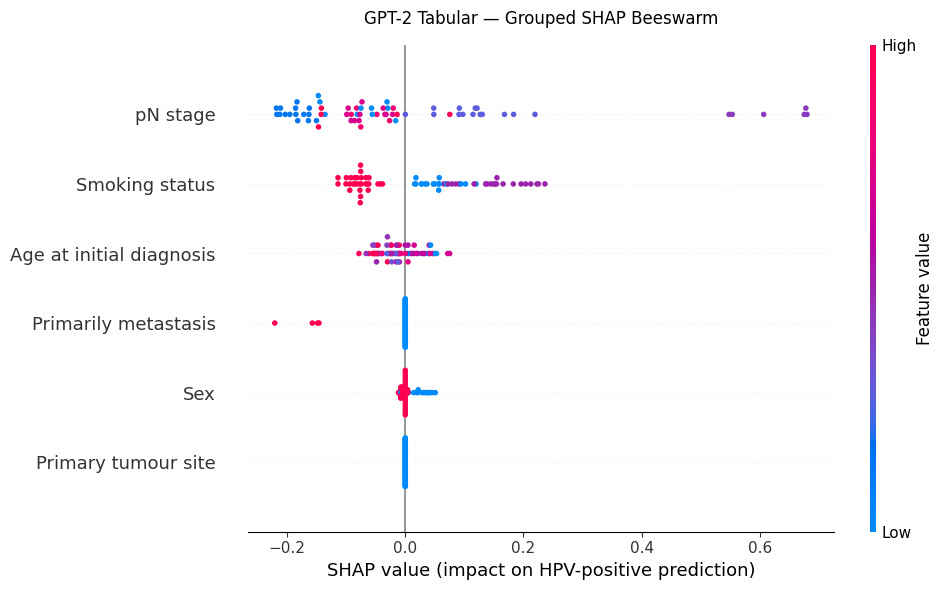

SHAP beeswarm saved: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Epoch148/GPT2_Epoch148_Grouped_SHAP_Beeswarm.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

# ------------------------------------------------------------
# GROUPED SHAP BEESWARM — STANDARD SHAP STYLE
# Six original clinical features
# Saves and downloads one high-resolution PNG
# ------------------------------------------------------------

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

print("Calculating grouped SHAP values...")

# Reproducible background sample
rng = np.random.default_rng(SEED)
background_size = min(20, len(X_train_np))

background_indices = rng.choice(
    len(X_train_np),
    size=background_size,
    replace=False
)

background = X_train_np[background_indices]

# SHAP explainer
explainer = shap.KernelExplainer(
    predict_positive_probability,
    background
)

shap_values = explainer.shap_values(
    X_test_np,
    nsamples=150
)

# Standardise SHAP output shape
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]

if shap_values.shape != X_test_np.shape:
    raise ValueError(
        f"Unexpected SHAP shape: {shap_values.shape}; "
        f"expected {X_test_np.shape}"
    )

# Group encoded SHAP contributions into six original features
grouped_shap = np.zeros(
    (len(X_test_np), len(original_features))
)

for j, name in enumerate(original_features):
    grouped_shap[:, j] = shap_values[
        :, group_indices[name]
    ].sum(axis=1)

# ------------------------------------------------------------
# Create grouped feature values for beeswarm colouring
# ------------------------------------------------------------

grouped_feature_values = np.zeros(
    (len(X_test_np), len(original_features))
)

for j, name in enumerate(original_features):

    indices = group_indices[name]

    if len(indices) == 1:
        # Continuous feature, e.g. age
        grouped_feature_values[:, j] = X_test_np[:, indices[0]]

    else:
        # One-hot encoded categorical feature:
        # use the active category index for colouring
        grouped_feature_values[:, j] = np.argmax(
            X_test_np[:, indices],
            axis=1
        )

# ------------------------------------------------------------
# Standard SHAP beeswarm
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

shap.summary_plot(
    grouped_shap,
    grouped_feature_values,
    feature_names=original_features,
    plot_type="dot",
    max_display=6,
    show=False,
    plot_size=(10, 6)
)

plt.title(
    "GPT-2 Tabular — Grouped SHAP Beeswarm",
    pad=15
)

plt.xlabel(
    "SHAP value (impact on HPV-positive prediction)"
)

plt.tight_layout()

shap_png = os.path.join(
    OUTPUT_DIR,
    "GPT2_Epoch148_Grouped_SHAP_Beeswarm.png"
)

plt.savefig(
    shap_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Save grouped SHAP data and importance
# ------------------------------------------------------------

shap_values_df = pd.DataFrame(
    grouped_shap,
    columns=original_features
)

shap_values_df.insert(
    0,
    "patient_id",
    patient_ids
)

shap_values_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_SHAP_Values.csv"
    ),
    index=False
)

shap_importance = pd.DataFrame({
    "Feature": original_features,
    "Mean_absolute_SHAP_value": np.mean(
        np.abs(grouped_shap),
        axis=0
    )
}).sort_values(
    "Mean_absolute_SHAP_value",
    ascending=False
)

shap_importance.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GPT2_Epoch148_Grouped_SHAP_Importance.csv"
    ),
    index=False
)

print("SHAP beeswarm saved:", shap_png)

# Download the PNG directly
files.download(shap_png)
